# Multiscale Image Compression with Wavelet Transforms

## 5.2 JPEG vs JPEG2000: A Practical Comparison

### 5.2.2 Visual Quality Demonstration

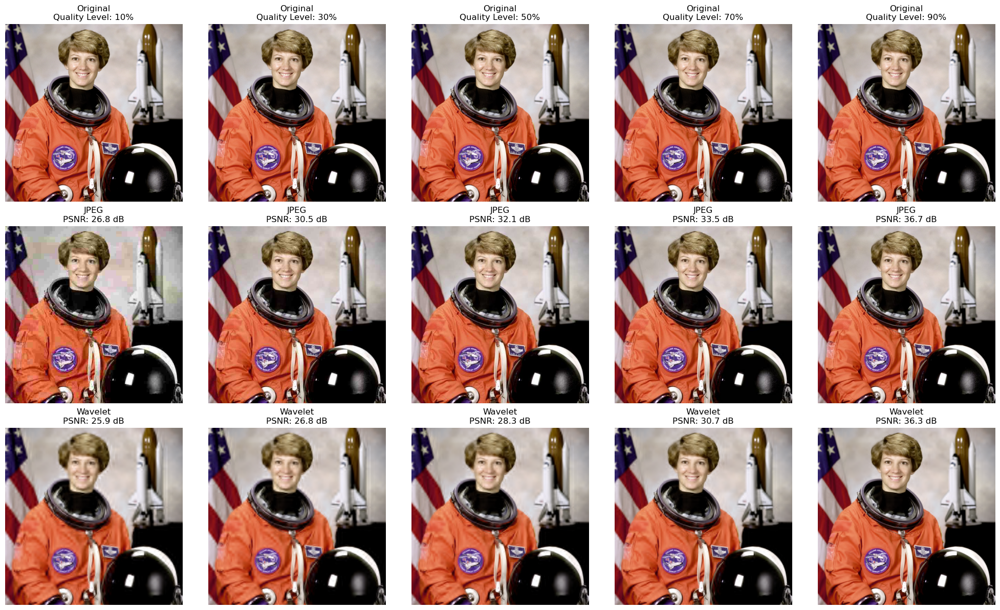

In [ ]:
import os
import pywt
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, io, metrics
import cv2
from typing import Optional, List, Union

class ColorWaveletCompressor:
    """
    Extended compressor for color images with advanced color space handling
    """
    
    def __init__(self, wavelet: str = 'db4', levels: int = 3, 
                 mode: str = 'symmetric', color_space: str = 'RGB'):
        """
        Initialize color image compressor
        
        Parameters:
        -----------
        wavelet : str
            Wavelet type ('haar', 'db4', 'coif2', 'bior2.2', etc.)
        levels : int
            Number of decomposition levels
        mode : str
            Boundary condition handling ('symmetric', 'periodization', etc.)
        color_space : str
            Color space for compression ('RGB', 'YUV', 'LAB', 'HSV')
        """
        self.wavelet = wavelet
        self.levels = levels
        self.mode = mode
        self.color_space = color_space
        self.supported_color_spaces = ['RGB', 'YUV', 'LAB', 'HSV']
        
        if wavelet not in pywt.wavelist():
            raise ValueError(f"Unsupported wavelet: {wavelet}")
        if color_space not in self.supported_color_spaces:
            raise ValueError(f"Unsupported color space: {color_space}")
    
    def load_and_prepare_color_image(self, source: Union[str, np.ndarray]) -> np.ndarray:
        """Load and prepare color image"""
        if isinstance(source, str):
            if not os.path.exists(source):
                raise FileNotFoundError(f"Image file not found: {source}")
            image = io.imread(source)
        else:
            image = source.copy()
        
        # Handle different formats
        if len(image.shape) == 2:
            # Grayscale - convert to RGB
            image = np.stack([image] * 3, axis=2)
        elif image.shape[2] == 4:
            # RGBA - convert to RGB
            image = color.rgba2rgb(image)
        
        # Normalize to 0-255 range
        if image.max() <= 1.0:
            image = (image * 255).astype(np.uint8)
        else:
            image = image.astype(np.uint8)
        
        return image
    
    def convert_color_space(self, image: np.ndarray, target_space: str) -> np.ndarray:
        """Convert image to target color space"""
        if target_space == 'RGB':
            return image
        elif target_space == 'YUV':
            return color.rgb2yuv(image)
        elif target_space == 'LAB':
            return color.rgb2lab(image)
        elif target_space == 'HSV':
            return color.rgb2hsv(image)
        else:
            raise ValueError(f"Unsupported color space: {target_space}")
    
    def convert_from_color_space(self, image: np.ndarray, source_space: str) -> np.ndarray:
        """Convert image from source color space back to RGB"""
        if source_space == 'RGB':
            return image
        elif source_space == 'YUV':
            return color.yuv2rgb(image)
        elif source_space == 'LAB':
            return color.lab2rgb(image)
        elif source_space == 'HSV':
            return color.hsv2rgb(image)
        else:
            raise ValueError(f"Unsupported color space: {source_space}")

def compress_color_image_advanced(
    image: np.ndarray, 
    wavelet: str = 'db4', 
    levels: int = 3,
    compression_ratio: float = 0.1,
    color_space: str = 'YUV',
    adaptive_channels: bool = True
) -> np.ndarray:
    """
    Advanced color image compression with native color space handling.
    
    Parameters
    ----------
    image : np.ndarray
        Input RGB image (uint8, [0,255])
    wavelet : str
        Wavelet type to use
    levels : int
        Number of decomposition levels
    compression_ratio : float
        Target compression ratio (0-1, e.g., 0.1 means stronger compression)
    color_space : str
        Color space for compression ('RGB', 'YUV', 'LAB', 'HSV')
    adaptive_channels : bool
        Whether to use different compression for luminance/chrominance
    
    Returns
    -------
    np.ndarray
        Compressed RGB image (uint8)
    """
    
    compressor = ColorWaveletCompressor(wavelet=wavelet, levels=levels, color_space=color_space)

    # Convert input to float64 in [0,1] before color space conversion
    work_image = image.astype(np.float64) / 255.0
    if color_space != 'RGB':
        work_image = compressor.convert_color_space(work_image, color_space)
    
    compressed_channels = []

    for channel_idx in range(work_image.shape[2]):
        channel_data = work_image[:, :, channel_idx]

        # Adjust compression depending on channel importance
        if adaptive_channels:
            if color_space == 'YUV' and channel_idx == 0:       # luminance
                channel_compression = compression_ratio * 0.7
            elif color_space == 'YUV' and channel_idx > 0:      # chrominance
                channel_compression = compression_ratio * 1.3
            elif color_space == 'LAB' and channel_idx == 0:     # L channel
                channel_compression = compression_ratio * 0.8
            else:
                channel_compression = compression_ratio
        else:
            channel_compression = compression_ratio

        # Wavelet decomposition
        coeffs = pywt.wavedec2(channel_data, wavelet, level=levels, mode='symmetric')

        # Collect all detail coefficients
        all_details = []
        for i in range(1, len(coeffs)):
            for detail in coeffs[i]:
                all_details.extend(detail.flatten())

        # Adaptive threshold (universal threshold style)
        if all_details:
            detail_std = np.std(all_details)
            threshold = detail_std * channel_compression * np.sqrt(2 * np.log(channel_data.size))
        else:
            threshold = 0

        # Apply soft thresholding to detail coefficients
        compressed_coeffs = list(coeffs)
        for i in range(1, len(coeffs)):
            compressed_coeffs[i] = tuple(
                pywt.threshold(detail, threshold, mode='soft')
                for detail in coeffs[i]
            )

        # Reconstruct channel
        reconstructed_channel = pywt.waverec2(compressed_coeffs, wavelet, mode='symmetric')

        # Clip to valid range for that color space
        if color_space == 'RGB':
            reconstructed_channel = np.clip(reconstructed_channel, 0, 1)
        elif color_space == 'HSV':
            reconstructed_channel = np.clip(reconstructed_channel, 0, 1)
        elif color_space == 'YUV':
            if channel_idx == 0:  # Y
                reconstructed_channel = np.clip(reconstructed_channel, 0, 1)
            else:  # U, V
                reconstructed_channel = np.clip(reconstructed_channel, -0.5, 0.5)
        elif color_space == 'LAB':
            if channel_idx == 0:  # L
                reconstructed_channel = np.clip(reconstructed_channel, 0, 100)
            elif channel_idx == 1:  # a
                reconstructed_channel = np.clip(reconstructed_channel, -128, 127)
            else:  # b
                reconstructed_channel = np.clip(reconstructed_channel, -128, 127)

        compressed_channels.append(reconstructed_channel)

    # Stack channels back
    compressed_image = np.stack(compressed_channels, axis=2)

    # Convert back to RGB
    if color_space != 'RGB':
        compressed_image = compressor.convert_from_color_space(compressed_image, color_space)

    # Clip and convert to uint8
    compressed_image = np.clip(compressed_image * 255, 0, 255)
    return compressed_image.astype(np.uint8)


def simulate_jpeg_compression(image: np.ndarray, quality: int) -> np.ndarray:
    """Simulate JPEG compression using OpenCV"""
    # Convert to format suitable for JPEG encoding
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)
    
    # Encode as JPEG with specified quality
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    result, encoded_image = cv2.imencode('.jpg', cv2.cvtColor(image, cv2.COLOR_RGB2BGR), encode_param)
    
    # Decode back to image
    decoded_image = cv2.imdecode(encoded_image, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decoded_image, cv2.COLOR_BGR2RGB)

def compare_jpeg_vs_wavelet(image_path: Optional[str] = None, quality_levels: List[int] = None):
    """
    Compare JPEG and wavelet compression at different quality levels
    
    Parameters:
    -----------
    image_path : str, optional
        Path to image file. If None, uses built-in test image
    quality_levels : list, optional
        List of quality levels to test
    """
    if quality_levels is None:
        quality_levels = [10, 30, 50, 70, 90]
    
    # Load test image
    if image_path is None:
        image = data.astronaut()
    else:
        image = io.imread(image_path)
    
    # Ensure RGB format
    if len(image.shape) == 3 and image.shape[2] == 4:  # RGBA to RGB
        image = image[:, :, :3]
    
    fig, axes = plt.subplots(3, len(quality_levels), figsize=(20, 12))
    
    for i, quality in enumerate(quality_levels):
        # JPEG compression simulation
        jpeg_compressed = simulate_jpeg_compression(image, quality)
        
        # Wavelet compression
        wavelet_compressed = compress_color_image_advanced(
            image, 
            compression_ratio=1.0 - (quality / 100.0)
        )
        
        # Original (top row)
        axes[0, i].imshow(image)
        axes[0, i].set_title(f'Original\nQuality Level: {quality}%')
        axes[0, i].axis('off')
        
        # JPEG (middle row)
        axes[1, i].imshow(jpeg_compressed)
        psnr_jpeg = metrics.peak_signal_noise_ratio(image, jpeg_compressed)
        axes[1, i].set_title(f'JPEG\nPSNR: {psnr_jpeg:.1f} dB')
        axes[1, i].axis('off')
        
        # Wavelet (bottom row)
        axes[2, i].imshow(wavelet_compressed)
        psnr_wavelet = metrics.peak_signal_noise_ratio(image, wavelet_compressed)
        axes[2, i].set_title(f'Wavelet\nPSNR: {psnr_wavelet:.1f} dB')
        axes[2, i].axis('off')
    
    plt.tight_layout()
    plt.savefig('./output/jpeg_vs_wavelet_comparison.png', dpi=300)
    plt.show()

# Run comparison
compare_jpeg_vs_wavelet()

## 5.3 Grayscale Image Compression: Step-by-Step Implementation

### 5.3.1: Enhanced Environment Setup

In [24]:
import os
import pywt
import numpy as np
from skimage import data, color, io, filters
from typing import Union, Dict
from scipy.stats import entropy

class WaveletCompressor:
    """
    Professional wavelet-based image compressor with full pipeline support
    """
    
    def __init__(self, wavelet: str = 'db4', levels: int = 3, mode: str = 'symmetric'):
        self.wavelet = wavelet
        self.levels = levels
        self.mode = mode
        self.compression_history = []
        
        if wavelet not in pywt.wavelist():
            raise ValueError(f"Unsupported wavelet: {wavelet}")
    
    def load_and_prepare_image(self, source: Union[str, np.ndarray], grayscale: bool = True) -> np.ndarray:
        """Load and prepare image for compression"""
        if isinstance(source, str):
            if not os.path.exists(source):
                raise FileNotFoundError(f"Image file not found: {source}")
            image = io.imread(source)
        else:
            image = source.copy()
        
        if grayscale:
            if len(image.shape) == 3:
                if image.shape[2] == 4:  # RGBA
                    image = color.rgba2rgb(image)
                image = color.rgb2gray(image)
        
        if image.max() <= 1.0:
            image = (image * 255).astype(np.uint8)
        else:
            image = image.astype(np.uint8)
        
        return image
    
    def analyze_image_properties(self, image: np.ndarray) -> Dict:
        """Analyze image properties for optimal compression"""
        return {
            'shape': image.shape,
            'dtype': str(image.dtype),
            'size_bytes': image.nbytes,
            'min_value': float(image.min()),
            'max_value': float(image.max()),
            'mean': float(image.mean()),
            'std': float(image.std()),
            'dynamic_range': float(image.max() - image.min()),
            'entropy': self._calculate_entropy(image),
            'edge_density': self._calculate_edge_density(image)
        }
    
    def _calculate_entropy(self, image: np.ndarray) -> float:
        """Calculate Shannon entropy of the grayscale distribution"""
        hist, _ = np.histogram(image, bins=256, range=(0, 255), density=True)
        return float(entropy(hist, base=2))
    
    def _calculate_edge_density(self, image: np.ndarray) -> float:
        """Calculate edge density using Sobel operator"""
        edges = filters.sobel(image / 255.0)
        return float(np.mean(edges > 0.1))


# Example usage
compressor = WaveletCompressor(wavelet='db4', levels=3)
test_image = compressor.load_and_prepare_image(data.camera())
properties = compressor.analyze_image_properties(test_image)

print("Image Analysis:")
print("-" * 50)
for key, value in properties.items():
    if isinstance(value, float):
        print(f"{key:<15}: {value:.3f}")
    else:
        print(f"{key:<15}: {value}")


Image Analysis:
--------------------------------------------------
shape          : (512, 512)
dtype          : uint8
size_bytes     : 262144
min_value      : 0.000
max_value      : 255.000
mean           : 129.061
std            : 73.645
dynamic_range  : 255.000
entropy        : 7.232
edge_density   : 0.080


### 5.3.2: Advanced Wavelet Decomposition with Visualization

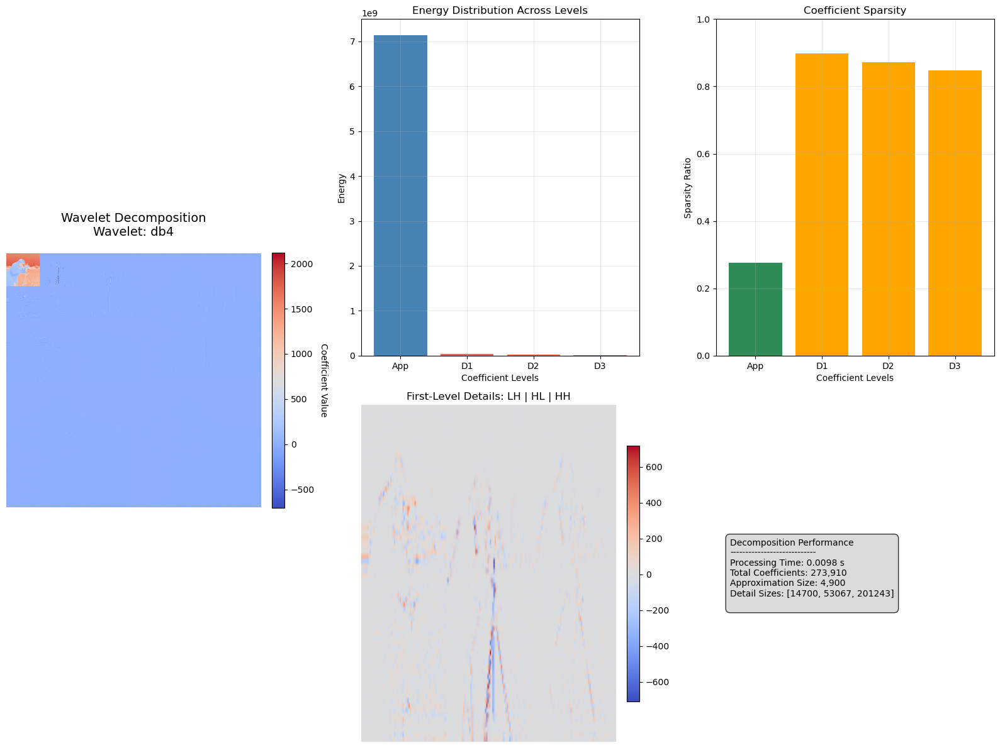

In [ ]:
def enhanced_wavelet_decomposition(
    compressor: WaveletCompressor,
    image: np.ndarray,
    visualize: bool = True
) -> Tuple[List, Dict]:
    """
    Perform enhanced wavelet decomposition with detailed coefficient analysis.

    Parameters
    ----------
    compressor : WaveletCompressor
        Initialized compressor instance containing wavelet, levels, and mode.
    image : np.ndarray
        Input grayscale image (2D array).
    visualize : bool, default=True
        Whether to generate visualization plots.

    Returns
    -------
    coeffs : list
        Wavelet decomposition coefficients from pywt.wavedec2.
    analysis : dict
        Dictionary containing:
        - decomposition_time (float): elapsed time in seconds
        - total_coefficients (int): total number of coefficients
        - approximation_size (int): size of approximation coefficients
        - detail_sizes (list[int]): sizes of detail subbands per level
        - coefficient_stats (list[dict]): statistics per level
    """

    start_time = time.time()
    coeffs = pywt.wavedec2(
        image,
        compressor.wavelet,
        level=compressor.levels,
        mode=compressor.mode
    )
    decomp_time = time.time() - start_time

    # Count coefficients recursively
    def count_coeffs(c):
        if isinstance(c, np.ndarray):
            return c.size
        return sum(count_coeffs(sub) for sub in c)

    # Global analysis
    analysis = {
        "decomposition_time": decomp_time,
        "total_coefficients": sum(count_coeffs(c) for c in coeffs),
        "approximation_size": coeffs[0].size,
        "detail_sizes": [sum(count_coeffs(sub) for sub in level) for level in coeffs[1:]],
        "coefficient_stats": []
    }

    # Per-level analysis
    for i, coeff_level in enumerate(coeffs):
        if i == 0:  # Approximation
            values = coeff_level.flatten()
            label = "Approximation"
        else:  # Detail coefficients
            values = np.concatenate([d.flatten() for d in coeff_level])
            label = f"Detail Level {i}"

        stats = {
            "level": label,
            "mean": float(np.mean(values)),
            "std": float(np.std(values)),
            "median": float(np.median(values)),
            "min": float(np.min(values)),
            "max": float(np.max(values)),
            "energy": float(np.sum(values**2)),
            "sparsity": float(np.mean(np.abs(values) < np.std(values)))
        }
        analysis["coefficient_stats"].append(stats)

    if visualize:
        _visualize_decomposition(coeffs, compressor.wavelet, analysis)

    return coeffs, analysis


def _visualize_decomposition(coeffs: List, wavelet: str, analysis: Dict):
    """Create comprehensive visualization of wavelet decomposition and stats."""

    arr, _ = pywt.coeffs_to_array(coeffs)

    fig = plt.figure(figsize=(16, 12))

    # --- Main decomposition visualization ---
    ax1 = plt.subplot(2, 3, (1, 4))
    im = ax1.imshow(arr, cmap="coolwarm", aspect="equal")
    ax1.set_title(
        f"Wavelet Decomposition\nWavelet: {wavelet}",
        fontsize=14, pad=20
    )
    ax1.axis("off")
    cbar = plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
    cbar.ax.set_ylabel("Coefficient Value", rotation=270, labelpad=15)

    # --- Energy distribution ---
    ax2 = plt.subplot(2, 3, 2)
    levels = [stat["level"] for stat in analysis["coefficient_stats"]]
    energies = [stat["energy"] for stat in analysis["coefficient_stats"]]
    ax2.bar(
        range(len(levels)),
        energies,
        color=["steelblue" if "App" in lvl else "tomato" for lvl in levels]
    )
    ax2.set_xlabel("Coefficient Levels")
    ax2.set_ylabel("Energy")
    ax2.set_title("Energy Distribution Across Levels")
    ax2.set_xticks(range(len(levels)))
    ax2.set_xticklabels(
        ["App"] + [f"D{i}" for i in range(1, len(levels))]
    )

    # --- Sparsity ---
    ax3 = plt.subplot(2, 3, 3)
    sparsities = [stat["sparsity"] for stat in analysis["coefficient_stats"]]
    ax3.bar(
        range(len(levels)),
        sparsities,
        color=["seagreen" if "App" in lvl else "orange" for lvl in levels]
    )
    ax3.set_xlabel("Coefficient Levels")
    ax3.set_ylabel("Sparsity Ratio")
    ax3.set_title("Coefficient Sparsity")
    ax3.set_ylim(0, 1)
    ax3.set_xticks(range(len(levels)))
    ax3.set_xticklabels(
        ["App"] + [f"D{i}" for i in range(1, len(levels))]
    )

    # --- First level detail visualization ---
    ax4 = plt.subplot(2, 3, 5)
    if len(coeffs) > 1:
        cH, cV, cD = coeffs[1]
        combined_details = np.hstack([cH, cV, cD])
        im_details = ax4.imshow(combined_details, cmap="coolwarm", aspect="auto")
        ax4.set_title("First-Level Details: LH | HL | HH")
        ax4.axis("off")
        plt.colorbar(im_details, ax=ax4, fraction=0.046, pad=0.04)

    # --- Metrics summary ---
    ax5 = plt.subplot(2, 3, 6)
    ax5.axis("off")
    metrics_text = (
        f"Decomposition Performance\n"
        f"----------------------------\n"
        f"Processing Time: {analysis['decomposition_time']:.4f} s\n"
        f"Total Coefficients: {analysis['total_coefficients']:,}\n"
        f"Approximation Size: {analysis['approximation_size']:,}\n"
        f"Detail Sizes: {analysis['detail_sizes']}\n"
    )
    ax5.text(
        0.05, 0.5, metrics_text, transform=ax5.transAxes,
        fontsize=10, va="center", ha="left",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.8)
    )

    plt.tight_layout()
    plt.savefig('./output/wavelet_decomposition_analysis.png', dpi=300)
    plt.show()

# Run enhanced decomposition
coeffs, analysis = enhanced_wavelet_decomposition(compressor, test_image, visualize=True)

### 5.3.3: Intelligent Compression with Adaptive Thresholding

Testing Intelligent Compression Methods:
Method: fixed, Target SSIM: 0.95, Achieved SSIM: 0.950
Method: adaptive, Target SSIM: 0.95, Achieved SSIM: 0.716
Method: smart, Target SSIM: 0.95, Achieved SSIM: 0.681
Method: fixed, Target SSIM: 0.9, Achieved SSIM: 0.901
Method: adaptive, Target SSIM: 0.9, Achieved SSIM: 0.692
Method: smart, Target SSIM: 0.9, Achieved SSIM: 0.674
Method: fixed, Target SSIM: 0.85, Achieved SSIM: 0.851
Method: adaptive, Target SSIM: 0.85, Achieved SSIM: 0.680
Method: smart, Target SSIM: 0.85, Achieved SSIM: 0.670


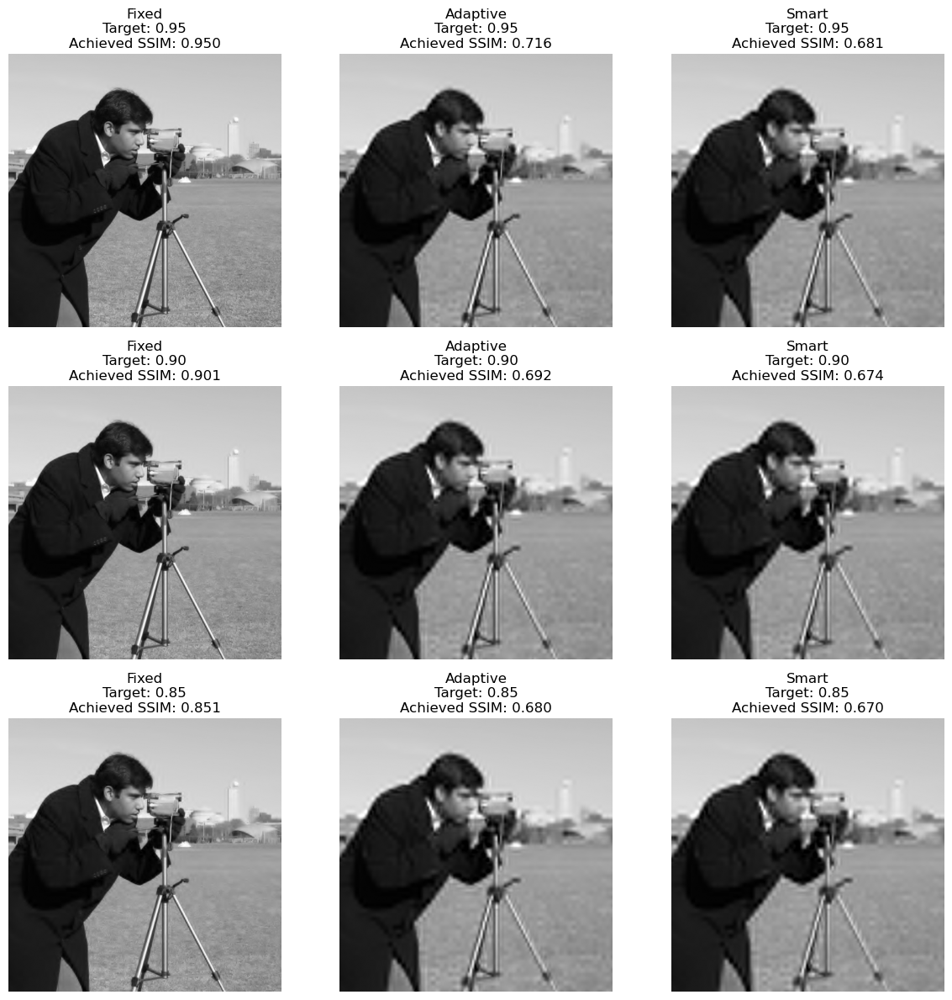

In [ ]:
import os
import time
import numpy as np
import pywt
import matplotlib.pyplot as plt
from typing import List, Dict, Tuple

from skimage import data, io, color, filters, metrics
from skimage.util import img_as_ubyte

def intelligent_compress(compressor: WaveletCompressor, image: np.ndarray, 
                        target_quality: float = 0.95, method: str = 'adaptive') -> Dict:
    """
    Intelligent compression with automatic parameter optimization
    
    Parameters:
    -----------
    compressor : WaveletCompressor
        Initialized compressor instance
    image : np.ndarray
        Input image
    target_quality : float
        Target SSIM quality (0-1)
    method : str
        Thresholding method ('fixed', 'adaptive', 'smart')
    
    Returns:
    --------
    dict : Comprehensive compression results
    """
    
    # Decompose image
    coeffs = pywt.wavedec2(image, compressor.wavelet, 
                          level=compressor.levels, mode=compressor.mode)
    
    results = {
        'original_image': image.copy(),
        'method': method,
        'target_quality': target_quality,
        'wavelet': compressor.wavelet,
        'levels': compressor.levels
    }
    
    if method == 'fixed':
        threshold = _find_optimal_fixed_threshold(coeffs, image, target_quality, compressor)
        compressed_coeffs = _apply_fixed_threshold(coeffs, threshold)
        results['threshold'] = threshold
        
    elif method == 'adaptive':
        compressed_coeffs, thresholds = _apply_adaptive_threshold(coeffs, target_quality)
        results['thresholds'] = thresholds
        
    elif method == 'smart':
        compressed_coeffs, params = _apply_smart_threshold(coeffs, image, target_quality, compressor)
        results['smart_params'] = params
    
    # Reconstruct image
    start_time = time.time()
    reconstructed = pywt.waverec2(compressed_coeffs, compressor.wavelet, mode=compressor.mode)
    reconstruction_time = time.time() - start_time
    
    # Ensure proper data range
    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
    
    # Calculate comprehensive metrics
    metrics_dict = _calculate_comprehensive_metrics(image, reconstructed)
    
    # Calculate compression statistics
    compression_stats = _calculate_compression_stats(coeffs, compressed_coeffs)
    
    # Compile final results
    results.update({
        'compressed_image': reconstructed,
        'reconstruction_time': reconstruction_time,
        'metrics': metrics_dict,
        'compression_stats': compression_stats,
        'achieved_quality': metrics_dict['ssim']
    })
    
    return results

def _find_optimal_fixed_threshold(coeffs: List, original: np.ndarray, 
                                 target_quality: float, compressor: WaveletCompressor) -> float:
    """Binary search for optimal fixed threshold"""
    
    def quality_for_threshold(threshold):
        compressed_coeffs = _apply_fixed_threshold(coeffs, threshold)
        reconstructed = pywt.waverec2(compressed_coeffs, compressor.wavelet, mode=compressor.mode)
        reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
        return metrics.structural_similarity(original, reconstructed, data_range=255)
    
    # Binary search
    low, high = 0.0, 100.0
    tolerance = 0.001
    max_iterations = 20
    
    for _ in range(max_iterations):
        mid = (low + high) / 2.0
        current_quality = quality_for_threshold(mid)
        
        if abs(current_quality - target_quality) < tolerance:
            return mid
        elif current_quality > target_quality:
            low = mid
        else:
            high = mid
    
    return (low + high) / 2.0

def _apply_fixed_threshold(coeffs: List, threshold: float) -> List:
    """Apply fixed threshold to all detail coefficients"""
    compressed_coeffs = list(coeffs)
    compressed_coeffs[0] = coeffs[0]  # Keep approximation unchanged
    
    for i in range(1, len(coeffs)):
        compressed_coeffs[i] = tuple([
            pywt.threshold(detail, threshold, mode='soft') 
            for detail in coeffs[i]
        ])
    
    return compressed_coeffs

def _apply_adaptive_threshold(coeffs: List, target_quality: float) -> Tuple[List, List]:
    """Apply adaptive thresholding based on coefficient statistics"""
    
    compressed_coeffs = list(coeffs)
    compressed_coeffs[0] = coeffs[0]  # Keep approximation
    thresholds = []
    
    # Calculate base threshold from all detail coefficients
    all_details = []
    for i in range(1, len(coeffs)):
        for detail in coeffs[i]:
            all_details.extend(detail.flatten())
    
    base_threshold = np.std(all_details) * (1 - target_quality) * 3
    
    for i in range(1, len(coeffs)):
        level_thresholds = []
        compressed_details = []
        
        for j, detail in enumerate(coeffs[i]):
            # Calculate adaptive threshold based on local statistics
            local_std = np.std(detail)
            local_mean = np.abs(np.mean(detail))
            
            # Scale threshold based on detail characteristics
            scale_factor = 1.0 + (local_std / (local_mean + 1e-10)) * 0.5
            adaptive_threshold = base_threshold * scale_factor / (i ** 0.5)  # Decrease with level
            
            compressed_detail = pywt.threshold(detail, adaptive_threshold, mode='soft')
            compressed_details.append(compressed_detail)
            level_thresholds.append(adaptive_threshold)
        
        compressed_coeffs[i] = tuple(compressed_details)
        thresholds.append(level_thresholds)
    
    return compressed_coeffs, thresholds

def _apply_smart_threshold(coeffs: List, original: np.ndarray, 
                          target_quality: float, compressor: WaveletCompressor) -> Tuple[List, Dict]:
    """Smart thresholding using perceptual importance weighting"""
    
    # Analyze image content for perceptual importance
    edge_map = filters.sobel(original)
    edge_strength = np.mean(edge_map)
    
    # Calculate texture measures
    texture_map = filters.rank.entropy(original, np.ones((9, 9)))
    texture_strength = np.mean(texture_map)
    
    params = {
        'edge_strength': float(edge_strength),
        'texture_strength': float(texture_strength),
        'content_type': 'detailed' if edge_strength > 0.1 else 'smooth'
    }
    
    # Adjust thresholding strategy based on content
    if params['content_type'] == 'detailed':
        # Preserve more details for edge-rich images
        quality_factor = target_quality * 1.2
        base_threshold_scale = 0.8
    else:
        # More aggressive compression for smooth images
        quality_factor = target_quality * 0.9
        base_threshold_scale = 1.2
    
    # Apply content-aware thresholding
    compressed_coeffs, thresholds = _apply_adaptive_threshold(coeffs, quality_factor)
    
    # Fine-tune based on content analysis
    for i in range(1, len(compressed_coeffs)):
        adjusted_details = []
        for j, detail in enumerate(compressed_coeffs[i]):
            # Additional refinement based on local content
            if params['content_type'] == 'detailed' and j == 0:  # Horizontal details
                # Preserve horizontal edges more
                detail = detail * 1.1
            adjusted_details.append(detail)
        compressed_coeffs[i] = tuple(adjusted_details)
    
    params['thresholds'] = thresholds
    params['base_threshold_scale'] = base_threshold_scale
    
    return compressed_coeffs, params

def _calculate_comprehensive_metrics(original: np.ndarray, compressed: np.ndarray) -> Dict:
    """Calculate comprehensive quality metrics"""
    
    # Ensure same data type
    original = original.astype(np.float64)
    compressed = compressed.astype(np.float64)
    
    metrics_dict = {}
    
    # Basic metrics
    mse = np.mean((original - compressed) ** 2)
    metrics_dict['mse'] = float(mse)
    
    if mse == 0:
        metrics_dict['psnr'] = float('inf')
    else:
        metrics_dict['psnr'] = float(20 * np.log10(255.0 / np.sqrt(mse)))
    
    # Structural similarity
    metrics_dict['ssim'] = float(metrics.structural_similarity(
        original, compressed, data_range=255, multichannel=False
    ))
    
    # Additional perceptual metrics
    metrics_dict['mae'] = float(np.mean(np.abs(original - compressed)))
    
    return metrics_dict

def _calculate_compression_stats(original_coeffs: List, compressed_coeffs: List) -> Dict:
    """Calculate detailed compression statistics"""
    
    def count_nonzero_coeffs(coeffs):
        total = 0
        for coeff in coeffs:
            if isinstance(coeff, np.ndarray):
                total += np.count_nonzero(coeff)
            else:
                total += sum(np.count_nonzero(c) for c in coeff)
        return total
    
    def calculate_energy(coeffs):
        total_energy = 0
        for coeff in coeffs:
            if isinstance(coeff, np.ndarray):
                total_energy += np.sum(coeff ** 2)
            else:
                total_energy += sum(np.sum(c ** 2) for c in coeff)
        return total_energy
    
    original_nonzero = count_nonzero_coeffs(original_coeffs)
    compressed_nonzero = count_nonzero_coeffs(compressed_coeffs)
    
    original_energy = calculate_energy(original_coeffs)
    compressed_energy = calculate_energy(compressed_coeffs)
    
    stats = {
        'original_nonzero_coeffs': original_nonzero,
        'compressed_nonzero_coeffs': compressed_nonzero,
        'sparsity_ratio': float(compressed_nonzero / original_nonzero),
        'compression_ratio': float(original_nonzero / compressed_nonzero),
        'zero_coeffs_percentage': float((original_nonzero - compressed_nonzero) / original_nonzero * 100),
        'energy_preservation': float(compressed_energy / original_energy),
        'energy_reduction_db': float(10 * np.log10(original_energy / compressed_energy)) if compressed_energy > 0 else float('inf')
    }
    
    return stats

# Demonstrate intelligent compression
print("Testing Intelligent Compression Methods:")
print("=" * 60)

methods = ['fixed', 'adaptive', 'smart']
target_qualities = [0.95, 0.90, 0.85]

results = []
for target_quality in target_qualities:
    for method in methods:
        result = intelligent_compress(compressor, test_image, target_quality, method)
        results.append(result)
        print(f"Method: {method}, Target SSIM: {target_quality}, Achieved SSIM: {result['achieved_quality']:.3f}")

# Visualize results
fig, axes = plt.subplots(len(target_qualities), len(methods), figsize=(12, 12))
for i, target_quality in enumerate(target_qualities):
    for j, method in enumerate(methods):
        idx = i * len(methods) + j
        axes[i, j].imshow(results[idx]['compressed_image'], cmap='gray')
        axes[i, j].set_title(f'{method.capitalize()}\nTarget: {target_quality:.2f}\nAchieved SSIM: {results[idx]["achieved_quality"]:.3f}')
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig('./output/intelligent_compression_comparison.png', dpi=300)    
plt.show()

## 5.4 Color Image Compression: Advanced Implementation
### 5.4.1 Color Space Analysis and Selection

Color Compression Analysis

Testing RGB color space, compression ratio: 0.05
  PSNR: 19.69 dB
  SSIM: 0.8946
  Processing time: 0.103 s

Testing YUV color space, compression ratio: 0.05
  PSNR: 3.98 dB
  SSIM: 0.3040
  Processing time: 0.130 s

Testing LAB color space, compression ratio: 0.05
  PSNR: 6.87 dB
  SSIM: 0.4137
  Processing time: 0.208 s

Testing HSV color space, compression ratio: 0.05
  PSNR: 30.49 dB
  SSIM: 0.9148
  Processing time: 0.204 s

Testing RGB color space, compression ratio: 0.1
  PSNR: 17.03 dB
  SSIM: 0.8463
  Processing time: 0.103 s

Testing YUV color space, compression ratio: 0.1
  PSNR: 4.01 dB
  SSIM: 0.3041
  Processing time: 0.130 s

Testing LAB color space, compression ratio: 0.1
  PSNR: 6.86 dB
  SSIM: 0.4100
  Processing time: 0.214 s

Testing HSV color space, compression ratio: 0.1
  PSNR: 26.54 dB
  SSIM: 0.8566
  Processing time: 0.204 s

Testing RGB color space, compression ratio: 0.2
  PSNR: 15.56 dB
  SSIM: 0.7990
  Processing time: 0.104 s



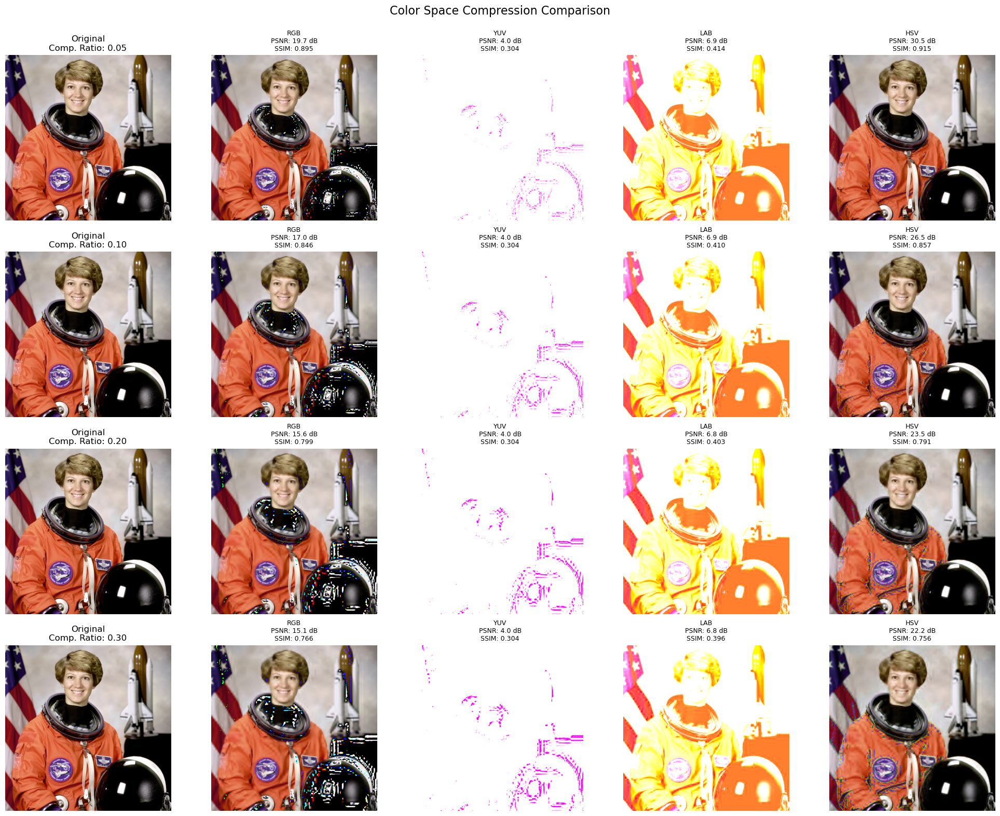

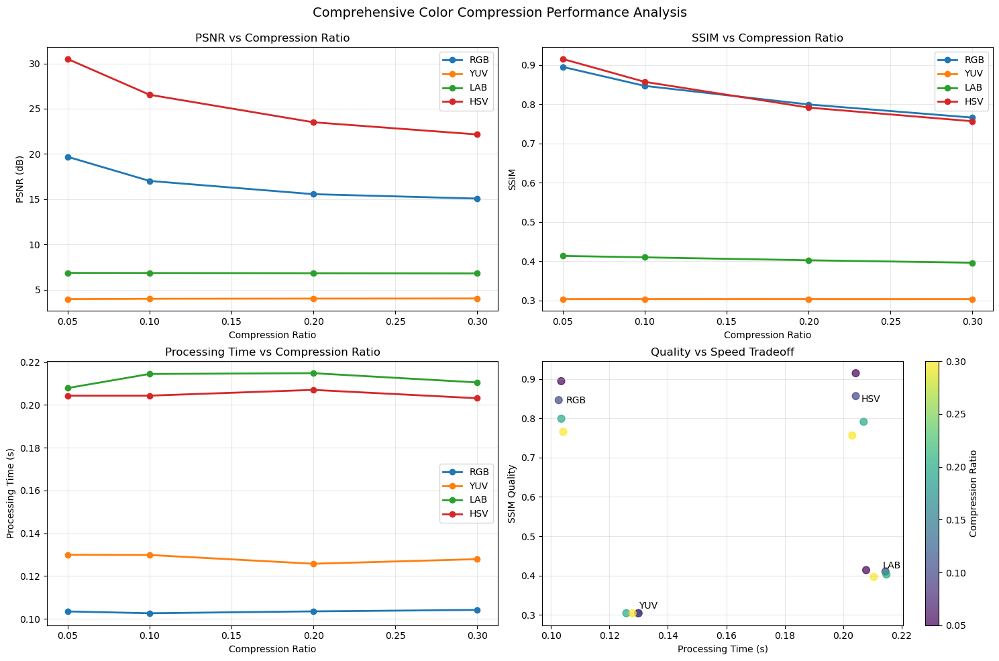

In [ ]:
import os
import time
import numpy as np
import pywt
import matplotlib.pyplot as plt
import pandas as pd
from typing import Union

from skimage import data, io, color, metrics


class ColorWaveletCompressor(WaveletCompressor):
    """
    Extended compressor for color images with advanced color space handling
    """
    
    def __init__(self, wavelet: str = 'db4', levels: int = 3, 
                 mode: str = 'symmetric', color_space: str = 'RGB'):
        """
        Initialize color image compressor
        
        Parameters:
        -----------
        color_space : str
            Color space for compression ('RGB', 'YUV', 'LAB', 'HSV')
        """
        super().__init__(wavelet, levels, mode)
        self.color_space = color_space
        self.supported_color_spaces = ['RGB', 'YUV', 'LAB', 'HSV']
        
        if color_space not in self.supported_color_spaces:
            raise ValueError(f"Unsupported color space: {color_space}")
    
    def load_and_prepare_color_image(self, source: Union[str, np.ndarray]) -> np.ndarray:
        """Load and prepare color image"""
        if isinstance(source, str):
            if not os.path.exists(source):
                raise FileNotFoundError(f"Image file not found: {source}")
            image = io.imread(source)
        else:
            image = source.copy()
        
        # Handle different formats
        if len(image.shape) == 2:
            # Grayscale - convert to RGB
            image = np.stack([image] * 3, axis=2)
        elif image.shape[2] == 4:
            # RGBA - convert to RGB
            image = color.rgba2rgb(image)
        
        # Normalize to 0-255 range
        if image.max() <= 1.0:
            image = (image * 255).astype(np.uint8)
        else:
            image = image.astype(np.uint8)
        
        return image
    
    def convert_color_space(self, image: np.ndarray, target_space: str) -> np.ndarray:
        """Convert image to target color space"""
        if target_space == 'RGB':
            return image
        elif target_space == 'YUV':
            return color.rgb2yuv(image)
        elif target_space == 'LAB':
            return color.rgb2lab(image)
        elif target_space == 'HSV':
            return color.rgb2hsv(image)
        else:
            raise ValueError(f"Unsupported color space: {target_space}")
    
    def convert_from_color_space(self, image: np.ndarray, source_space: str) -> np.ndarray:
        """Convert image from source color space back to RGB"""
        if source_space == 'RGB':
            return image
        elif source_space == 'YUV':
            return color.yuv2rgb(image)
        elif source_space == 'LAB':
            return color.lab2rgb(image)
        elif source_space == 'HSV':
            return color.hsv2rgb(image)
        else:
            raise ValueError(f"Unsupported color space: {source_space}")

def compress_color_image_advanced(image: np.ndarray, 
                                 wavelet: str = 'db4', 
                                 levels: int = 3,
                                 compression_ratio: float = 0.1,
                                 color_space: str = 'YUV',
                                 adaptive_channels: bool = True) -> np.ndarray:
    """
    Advanced color image compression with multiple optimization strategies
    
    Parameters:
    -----------
    image : np.ndarray
        Input RGB image
    wavelet : str
        Wavelet type to use
    levels : int
        Number of decomposition levels
    compression_ratio : float
        Target compression ratio (0-1, where 0.1 means 90% compression)
    color_space : str
        Color space for compression
    adaptive_channels : bool
        Whether to use different compression for each channel
    
    Returns:
    --------
    np.ndarray : Compressed RGB image
    """
    
    # Initialize color compressor
    compressor = ColorWaveletCompressor(wavelet=wavelet, levels=levels, color_space=color_space)
    
    # Convert to target color space
    if color_space != 'RGB':
        work_image = compressor.convert_color_space(image.astype(np.float64) / 255.0, color_space)
        # Normalize for wavelet processing
        if color_space in ['YUV', 'LAB']:
            work_image = (work_image - work_image.min()) / (work_image.max() - work_image.min()) * 255
        else:
            work_image = work_image * 255
    else:
        work_image = image.astype(np.float64)
    
    compressed_channels = []
    channel_names = ['R/Y/L/H', 'G/U/A/S', 'B/V/B/V'][0:work_image.shape[2]]
    
    for channel_idx in range(work_image.shape[2]):
        channel_data = work_image[:, :, channel_idx].astype(np.float64)
        
        # Adaptive channel-specific compression
        if adaptive_channels:
            if color_space == 'YUV' and channel_idx == 0:
                # Luminance channel - preserve more detail
                channel_compression = compression_ratio * 0.7
            elif color_space == 'YUV' and channel_idx > 0:
                # Chrominance channels - can compress more aggressively
                channel_compression = compression_ratio * 1.3
            elif color_space == 'LAB' and channel_idx == 0:
                # L channel - preserve detail
                channel_compression = compression_ratio * 0.8
            else:
                # Default compression
                channel_compression = compression_ratio
        else:
            channel_compression = compression_ratio
        
        # Perform wavelet compression
        coeffs = pywt.wavedec2(channel_data, wavelet, level=levels, mode='symmetric')
        
        # Calculate adaptive threshold
        all_details = []
        for i in range(1, len(coeffs)):
            for detail in coeffs[i]:
                all_details.extend(detail.flatten())
        
        if all_details:
            detail_std = np.std(all_details)
            threshold = detail_std * channel_compression * 5  # Scale factor for threshold
        else:
            threshold = 0
        
        # Apply thresholding
        compressed_coeffs = list(coeffs)
        compressed_coeffs[0] = coeffs[0]  # Keep approximation
        
        for i in range(1, len(coeffs)):
            compressed_coeffs[i] = tuple([
                pywt.threshold(detail, threshold, mode='soft') 
                for detail in coeffs[i]
            ])
        
        # Reconstruct channel
        reconstructed_channel = pywt.waverec2(compressed_coeffs, wavelet, mode='symmetric')
        compressed_channels.append(reconstructed_channel)
    
    # Combine channels
    compressed_image = np.stack(compressed_channels, axis=2)
    
    # Convert back to RGB if necessary
    if color_space != 'RGB':
        if color_space in ['YUV', 'LAB']:
            # Denormalize first
            compressed_image = compressed_image / 255.0 * (work_image.max() - work_image.min()) + work_image.min()
        else:
            compressed_image = compressed_image / 255.0
        
        compressed_image = compressor.convert_from_color_space(compressed_image, color_space)
        compressed_image = np.clip(compressed_image * 255, 0, 255)
    
    return compressed_image.astype(np.uint8)

def analyze_color_compression_performance():
    """Comprehensive analysis of color compression across different color spaces"""
    
    # Load test color image
    test_color_image = data.astronaut()
    
    color_spaces = ['RGB', 'YUV', 'LAB', 'HSV']
    compression_ratios = [0.05, 0.1, 0.2, 0.3]
    
    results_data = []
    
    print("Color Compression Analysis")
    print("=" * 50)
    
    fig, axes = plt.subplots(len(compression_ratios), len(color_spaces) + 1, 
                           figsize=(20, 16))
    
    for i, comp_ratio in enumerate(compression_ratios):
        # Show original
        axes[i, 0].imshow(test_color_image)
        axes[i, 0].set_title(f'Original\nComp. Ratio: {comp_ratio:.2f}')
        axes[i, 0].axis('off')
        
        for j, color_space in enumerate(color_spaces):
            print(f"\nTesting {color_space} color space, compression ratio: {comp_ratio}")
            
            try:
                start_time = time.time()
                compressed = compress_color_image_advanced(
                    test_color_image, 
                    compression_ratio=comp_ratio, 
                    color_space=color_space,
                    adaptive_channels=True
                )
                processing_time = time.time() - start_time
                
                # Calculate metrics
                psnr = metrics.peak_signal_noise_ratio(test_color_image, compressed)
                ssim = metrics.structural_similarity(
                    test_color_image, compressed, 
                    multichannel=True, channel_axis=2, data_range=255
                )
                
                # Display result
                axes[i, j + 1].imshow(compressed)
                title = f'{color_space}\nPSNR: {psnr:.1f} dB\nSSIM: {ssim:.3f}'
                axes[i, j + 1].set_title(title, fontsize=9)
                axes[i, j + 1].axis('off')
                
                # Store results
                results_data.append({
                    'color_space': color_space,
                    'compression_ratio': comp_ratio,
                    'psnr': psnr,
                    'ssim': ssim,
                    'processing_time': processing_time
                })
                
                print(f"  PSNR: {psnr:.2f} dB")
                print(f"  SSIM: {ssim:.4f}")
                print(f"  Processing time: {processing_time:.3f} s")
                
            except Exception as e:
                print(f"  Error: {e}")
                axes[i, j + 1].text(0.5, 0.5, f'Error:\n{str(e)[:30]}...', 
                                   ha='center', va='center', 
                                   transform=axes[i, j + 1].transAxes)
                axes[i, j + 1].axis('off')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)  # leave extra space for supertitle
    plt.suptitle('Color Space Compression Comparison', fontsize=16, y=0.98)
    plt.savefig('./output/color_compression_comparison.png', dpi=300)
    plt.show()
    
    # Create performance summary
    df = pd.DataFrame(results_data)
    
    # Performance comparison plots
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # PSNR comparison
    for color_space in color_spaces:
        subset = df[df['color_space'] == color_space]
        axes[0, 0].plot(subset['compression_ratio'], subset['psnr'], 
                       'o-', label=color_space, linewidth=2, markersize=6)
    axes[0, 0].set_xlabel('Compression Ratio')
    axes[0, 0].set_ylabel('PSNR (dB)')
    axes[0, 0].set_title('PSNR vs Compression Ratio')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # SSIM comparison
    for color_space in color_spaces:
        subset = df[df['color_space'] == color_space]
        axes[0, 1].plot(subset['compression_ratio'], subset['ssim'], 
                       'o-', label=color_space, linewidth=2, markersize=6)
    axes[0, 1].set_xlabel('Compression Ratio')
    axes[0, 1].set_ylabel('SSIM')
    axes[0, 1].set_title('SSIM vs Compression Ratio')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Processing time comparison
    for color_space in color_spaces:
        subset = df[df['color_space'] == color_space]
        axes[1, 0].plot(subset['compression_ratio'], subset['processing_time'], 
                       'o-', label=color_space, linewidth=2, markersize=6)
    axes[1, 0].set_xlabel('Compression Ratio')
    axes[1, 0].set_ylabel('Processing Time (s)')
    axes[1, 0].set_title('Processing Time vs Compression Ratio')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Quality vs Speed tradeoff
    axes[1, 1].scatter(df['processing_time'], df['ssim'], 
                      c=df['compression_ratio'], s=60, alpha=0.7, cmap='viridis')
    for color_space in color_spaces:
        subset = df[df['color_space'] == color_space].groupby('color_space').mean()
        axes[1, 1].annotate(color_space, 
                          (subset['processing_time'].iloc[0], subset['ssim'].iloc[0]),
                          xytext=(5, 5), textcoords='offset points', fontsize=10)
    
    cbar = plt.colorbar(axes[1, 1].collections[0], ax=axes[1, 1])
    cbar.set_label('Compression Ratio')
    axes[1, 1].set_xlabel('Processing Time (s)')
    axes[1, 1].set_ylabel('SSIM Quality')
    axes[1, 1].set_title('Quality vs Speed Tradeoff')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)  # leave extra space for supertitle
    plt.suptitle('Comprehensive Color Compression Performance Analysis', 
                 fontsize=14, y=0.98)
    plt.savefig('./output/color_compression_performance_analysis.png', dpi=300)
    plt.show()
    
    return df

# Run color compression analysis
color_analysis_results = analyze_color_compression_performance()

## 5.5: Performance Optimization and Benchmarking

### 5.5.1 Advanced Benchmarking Framework


In [41]:
import numpy as np
import pywt
import pandas as pd
import time
from typing import List, Dict
from skimage import color, metrics

class OptimizedWaveletCompressor:
    """
    Production-optimized wavelet compressor with caching and parallel processing.
    Handles image padding for safe wavelet decomposition.
    """
    
    def __init__(self, wavelet: str = 'db4', levels: int = 3, 
                 cache_size: int = 100, n_jobs: int = -1):
        self.wavelet = wavelet
        self.levels = levels
        self.cache_size = cache_size
        self.n_jobs = n_jobs
        self._decomposition_cache = {}
        self._cache_hits = 0
        self._cache_misses = 0

    @staticmethod
    def pad_image_for_wavelet(image: np.ndarray, levels: int) -> np.ndarray:
        """
        Pad image to size divisible by 2^levels for wavelet decomposition.
        """
        rows, cols = image.shape
        new_rows = (rows + 2**levels - 1) // (2**levels) * (2**levels)
        new_cols = (cols + 2**levels - 1) // (2**levels) * (2**levels)
        pad_rows = new_rows - rows
        pad_cols = new_cols - cols
        padded = np.pad(image, ((0, pad_rows), (0, pad_cols)), mode='symmetric')
        return padded

    def benchmark_wavelet_types(self, image: np.ndarray, 
                                wavelet_list: List[str] = None) -> pd.DataFrame:
        """
        Benchmark different wavelet types on the input image.
        Handles mixed image types and pads images for safe decomposition.
        """
        if wavelet_list is None:
            wavelet_list = ['haar', 'db4', 'db8', 'coif2', 'coif4', 'bior2.2', 'bior4.4']

        # Ensure image is 2D uint8
        if image.ndim == 3:
            image = color.rgb2gray(image) * 255
        image_uint8 = np.clip(image, 0, 255).astype(np.uint8)

        # Pad image to compatible size
        image_uint8 = self.pad_image_for_wavelet(image_uint8, self.levels)
        
        results = []
        threshold = 20  # Fixed threshold for fair comparison
        
        print(f"Benchmarking {len(wavelet_list)} wavelets...")
        print("-" * 60)
        
        for i, wavelet in enumerate(wavelet_list):
            print(f"Testing {wavelet} ({i+1}/{len(wavelet_list)})...")
            try:
                # Decomposition
                start_time = time.time()
                coeffs = pywt.wavedec2(image_uint8, wavelet, level=self.levels, mode='symmetric')
                decomp_time = time.time() - start_time
                
                # Compression (thresholding)
                start_time = time.time()
                compressed_coeffs = [coeffs[0]] + [
                    tuple([pywt.threshold(detail, threshold, mode='soft') for detail in level])
                    for level in coeffs[1:]
                ]
                compress_time = time.time() - start_time
                
                # Reconstruction
                start_time = time.time()
                reconstructed = pywt.waverec2(compressed_coeffs, wavelet, mode='symmetric')
                reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
                reconstruct_time = time.time() - start_time
                
                total_time = decomp_time + compress_time + reconstruct_time
                
                # Metrics
                psnr = metrics.peak_signal_noise_ratio(image_uint8, reconstructed)
                ssim = metrics.structural_similarity(image_uint8, reconstructed, data_range=255)
                
                original_nonzero = sum(
                    np.count_nonzero(coeff) if isinstance(coeff, np.ndarray)
                    else sum(np.count_nonzero(c) for c in coeff)
                    for coeff in coeffs
                )
                
                compressed_nonzero = sum(
                    np.count_nonzero(coeff) if isinstance(coeff, np.ndarray)
                    else sum(np.count_nonzero(c) for c in coeff)
                    for coeff in compressed_coeffs
                )
                
                compression_ratio = original_nonzero / compressed_nonzero if compressed_nonzero > 0 else float('inf')
                
                wavelet_info = pywt.Wavelet(wavelet)
                
                results.append({
                    'wavelet': wavelet,
                    'family': wavelet_info.family_name,
                    'vanishing_moments': getattr(wavelet_info, 'vanishing_moments_psi', 'N/A'),
                    'decomposition_time': decomp_time,
                    'compression_time': compress_time,
                    'reconstruction_time': reconstruct_time,
                    'total_time': total_time,
                    'psnr': psnr,
                    'ssim': ssim,
                    'compression_ratio': compression_ratio,
                    'original_nonzero': original_nonzero,
                    'compressed_nonzero': compressed_nonzero,
                    'memory_efficiency': compressed_nonzero / image_uint8.size
                })
                
                print(f"  Time: {total_time:.4f}s, PSNR: {psnr:.1f} dB, SSIM: {ssim:.3f}")
            
            except Exception as e:
                print(f"  Error with {wavelet}: {e}")
                continue
        
        df = pd.DataFrame(results)
        if df.empty:
            print("No successful wavelet decompositions!")
            return df
        return df.sort_values('total_time')

    def optimize_parameters(self, image: np.ndarray, 
                           target_psnr: float = 30.0,
                           max_iterations: int = 20) -> Dict:
        """
        Automatically optimize compression parameters for a target PSNR.
        """
        # Ensure 2D uint8
        if image.ndim == 3:
            image = color.rgb2gray(image) * 255
        image_uint8 = np.clip(image, 0, 255).astype(np.uint8)

        # Pad image for wavelet
        image_uint8 = self.pad_image_for_wavelet(image_uint8, self.levels)

        print(f"Optimizing parameters for target PSNR: {target_psnr} dB")
        print("-" * 50)
        
        best_result = None
        best_error = float('inf')
        
        threshold_range = (1.0, 100.0)
        level_range = (1, 5)
        
        for levels in range(level_range[0], level_range[1] + 1):
            print(f"Testing {levels} decomposition levels...")
            low_thresh, high_thresh = threshold_range
            
            for iteration in range(max_iterations):
                mid_thresh = (low_thresh + high_thresh) / 2.0
                try:
                    coeffs = pywt.wavedec2(image_uint8, self.wavelet, level=levels, mode='symmetric')
                    compressed_coeffs = [coeffs[0]] + [
                        tuple([pywt.threshold(detail, mid_thresh, mode='soft') for detail in level])
                        for level in coeffs[1:]
                    ]
                    reconstructed = pywt.waverec2(compressed_coeffs, self.wavelet, mode='symmetric')
                    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
                    
                    current_psnr = metrics.peak_signal_noise_ratio(image_uint8, reconstructed)
                    error = abs(current_psnr - target_psnr)
                    
                    if error < best_error:
                        best_error = error
                        best_result = {
                            'levels': levels,
                            'threshold': mid_thresh,
                            'achieved_psnr': current_psnr,
                            'psnr_error': error,
                            'ssim': metrics.structural_similarity(image_uint8, reconstructed, data_range=255)
                        }
                    
                    # Adjust search
                    if current_psnr > target_psnr:
                        low_thresh = mid_thresh
                    else:
                        high_thresh = mid_thresh
                    
                    if error < 0.1 or (high_thresh - low_thresh) < 0.01:
                        break
                    
                except Exception as e:
                    print(f"    Error at iteration {iteration}: {e}")
                    break
        
        if best_result:
            print(f"\nOptimization complete!")
            print(f"Best parameters: {best_result['levels']} levels, threshold: {best_result['threshold']:.2f}")
            print(f"Achieved PSNR: {best_result['achieved_psnr']:.2f} dB (target: {target_psnr:.2f} dB)")
            print(f"Error: {best_result['psnr_error']:.2f} dB")
            print(f"SSIM: {best_result['ssim']:.4f}")
        else:
            print("Optimization failed!")
        
        return best_result
    
from skimage import data

# Load a sample image (grayscale)
test_image = data.coins()

# Initialize compressor
compressor = OptimizedWaveletCompressor(wavelet='db4', levels=3)

# --- Run benchmark ---
print("\n=== Wavelet Benchmark ===")
df_results = compressor.benchmark_wavelet_types(test_image)
print(df_results.head())

# --- Run optimization ---
print("\n=== Parameter Optimization ===")
best_params = compressor.optimize_parameters(test_image, target_psnr=30.0)
print(best_params)


=== Wavelet Benchmark ===
Benchmarking 7 wavelets...
------------------------------------------------------------
Testing haar (1/7)...
  Time: 0.0049s, PSNR: 29.0 dB, SSIM: 0.814
Testing db4 (2/7)...
  Time: 0.0057s, PSNR: 29.1 dB, SSIM: 0.822
Testing db8 (3/7)...
  Time: 0.0070s, PSNR: 28.8 dB, SSIM: 0.815
Testing coif2 (4/7)...
  Time: 0.0114s, PSNR: 29.3 dB, SSIM: 0.822
Testing coif4 (5/7)...
  Time: 0.0079s, PSNR: 29.2 dB, SSIM: 0.820
Testing bior2.2 (6/7)...
  Time: 0.0040s, PSNR: 29.5 dB, SSIM: 0.841
Testing bior4.4 (7/7)...
  Time: 0.0043s, PSNR: 29.1 dB, SSIM: 0.821
   wavelet        family  vanishing_moments  decomposition_time  \
5  bior2.2  Biorthogonal                  2            0.001915   
6  bior4.4  Biorthogonal                  4            0.002110   
0     haar          Haar                  1            0.002351   
1      db4    Daubechies                  4            0.002893   
2      db8    Daubechies                  8            0.003712   

   compression

## 5.6 Compression Performance Metrics

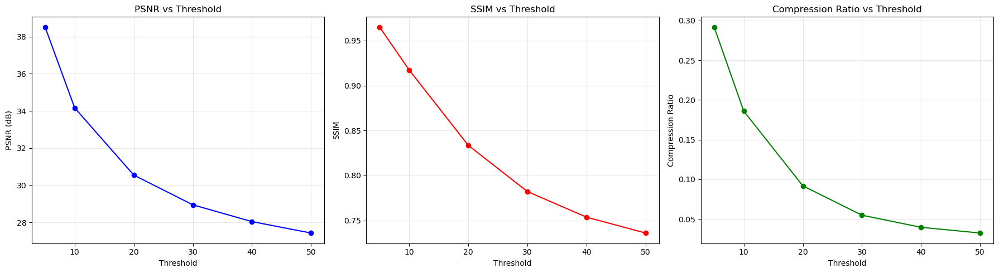


Compression Analysis Results:
------------------------------------------------------------
Threshold  PSNR (dB)  SSIM     Comp. Ratio 
------------------------------------------------------------
5          38.51      0.965    0.292       
10         34.16      0.917    0.186       
20         30.54      0.833    0.092       
30         28.94      0.782    0.055       
40         28.04      0.754    0.040       
50         27.42      0.736    0.032       


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage import metrics, color

def multilevel_compress(image, wavelet='db4', level=3, threshold=20):
    """
    Perform multilevel wavelet compression on an image.
    
    Returns:
    --------
    compressed_image : np.ndarray
        Reconstructed image after thresholding
    coeffs : list
        Original wavelet coefficients
    compressed_coeffs : list
        Thresholded wavelet coefficients
    """
    # Convert RGB to grayscale
    if image.ndim == 3:
        image = color.rgb2gray(image) * 255
    image = np.clip(image, 0, 255).astype(np.float64)
    
    # Pad image to compatible size
    rows, cols = image.shape
    new_rows = (rows + 2**level - 1) // (2**level) * (2**level)
    new_cols = (cols + 2**level - 1) // (2**level) * (2**level)
    pad_rows = new_rows - rows
    pad_cols = new_cols - cols
    image_padded = np.pad(image, ((0, pad_rows), (0, pad_cols)), mode='symmetric')
    
    # Wavelet decomposition
    coeffs = pywt.wavedec2(image_padded, wavelet, level=level, mode='symmetric')
    
    # Thresholding
    compressed_coeffs = [coeffs[0]] + [
        tuple([pywt.threshold(detail, threshold, mode='soft') for detail in level])
        for level in coeffs[1:]
    ]
    
    # Reconstruction
    compressed_image = pywt.waverec2(compressed_coeffs, wavelet, mode='symmetric')
    compressed_image = compressed_image[:rows, :cols]  # crop back to original size
    compressed_image = np.clip(compressed_image, 0, 255).astype(np.uint8)
    
    return compressed_image, coeffs, compressed_coeffs

def calculate_metrics(original, compressed):
    """Calculate MSE, PSNR, and SSIM between original and compressed images"""
    original = original.astype(np.float64)
    compressed = compressed.astype(np.float64)
    
    mse = np.mean((original - compressed) ** 2)
    psnr = float('inf') if mse == 0 else 20 * np.log10(255.0 / np.sqrt(mse))
    ssim = metrics.structural_similarity(original, compressed, data_range=255)
    
    return {'MSE': mse, 'PSNR': psnr, 'SSIM': ssim}

def compression_analysis(image, thresholds, wavelet='db4', level=3):
    """Analyze compression performance across different threshold values"""
    results = []
    compressed_images = []
    
    for threshold in thresholds:
        compressed, orig_coeffs, comp_coeffs = multilevel_compress(
            image, wavelet=wavelet, level=level, threshold=threshold
        )
        compressed_images.append(compressed)
        
        metrics_dict = calculate_metrics(image, compressed)
        metrics_dict['Threshold'] = threshold
        
        # Compute approximate compression ratio
        original_nonzero = sum(
            np.count_nonzero(coeff) if isinstance(coeff, np.ndarray)
            else sum(np.count_nonzero(c) for c in coeff)
            for coeff in orig_coeffs
        )
        compressed_nonzero = sum(
            np.count_nonzero(coeff) if isinstance(coeff, np.ndarray)
            else sum(np.count_nonzero(c) for c in coeff)
            for coeff in comp_coeffs
        )
        metrics_dict['Compression_Ratio'] = compressed_nonzero / original_nonzero
        results.append(metrics_dict)
    
    return results, compressed_images

def plot_compression_results(results, thresholds):
    """Plot PSNR, SSIM, and Compression Ratio vs Threshold"""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    psnr_values = [r['PSNR'] for r in results]
    ssim_values = [r['SSIM'] for r in results]
    ratio_values = [r['Compression_Ratio'] for r in results]
    
    axes[0].plot(thresholds, psnr_values, 'b-o')
    axes[0].set_xlabel('Threshold')
    axes[0].set_ylabel('PSNR (dB)')
    axes[0].set_title('PSNR vs Threshold')
    axes[0].grid(True)
    
    axes[1].plot(thresholds, ssim_values, 'r-o')
    axes[1].set_xlabel('Threshold')
    axes[1].set_ylabel('SSIM')
    axes[1].set_title('SSIM vs Threshold')
    axes[1].grid(True)
    
    axes[2].plot(thresholds, ratio_values, 'g-o')
    axes[2].set_xlabel('Threshold')
    axes[2].set_ylabel('Compression Ratio')
    axes[2].set_title('Compression Ratio vs Threshold')
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.savefig('./output/14.6_compression_analysis.png', dpi=300)
    plt.show()

def print_compression_results(results):
    """Print compression analysis in a formatted table"""
    print("\nCompression Analysis Results:")
    print("-" * 60)
    print(f"{'Threshold':<10} {'PSNR (dB)':<10} {'SSIM':<8} {'Comp. Ratio':<12}")
    print("-" * 60)
    for r in results:
        print(f"{r['Threshold']:<10} {r['PSNR']:<10.2f} {r['SSIM']:<8.3f} {r['Compression_Ratio']:<12.3f}")

# ============================
# Example Usage
# ============================

# thresholds to test
thresholds = [5, 10, 20, 30, 40, 50]

# Use any grayscale or RGB image
# For example, from skimage:
from skimage import data
test_image = data.camera()  # grayscale image

# Run analysis
results, compressed_imgs = compression_analysis(test_image, thresholds, wavelet='db4', level=3)
plot_compression_results(results, thresholds)
print_compression_results(results)


## 5.7 Practical Implementation Considerations

### 5.7.1 Edge Handling and Boundary Effects


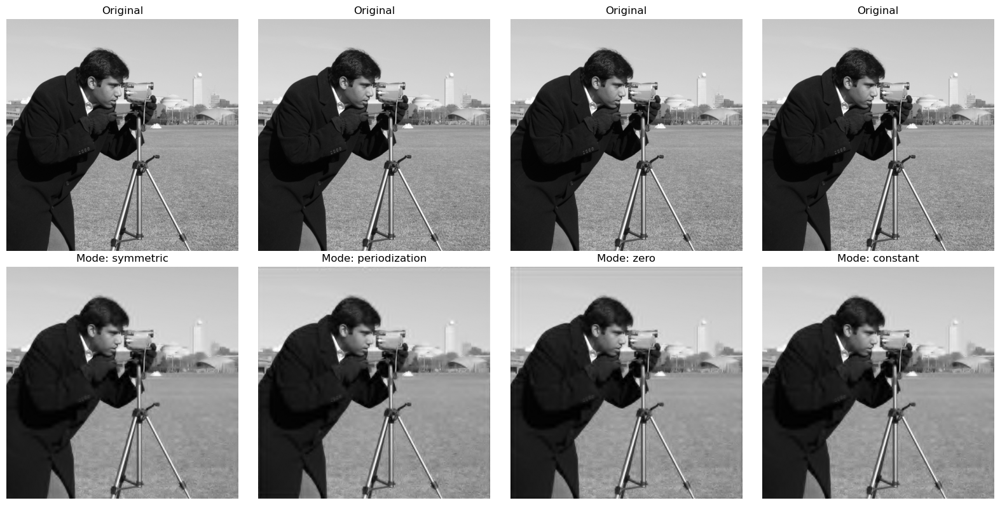

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pywt
from skimage import data

def compare_boundary_conditions(image, wavelet='db4'):
    """Compare different boundary condition handling methods"""
    
    modes = ['symmetric', 'periodization', 'zero', 'constant']
    fig, axes = plt.subplots(2, len(modes), figsize=(16, 8))
    
    for i, mode in enumerate(modes):
        # Decompose with specific boundary condition
        coeffs = pywt.wavedec2(image, wavelet, level=3, mode=mode)
        
        # Apply threshold
        coeffs_thresh = list(coeffs)
        coeffs_thresh[0] = coeffs[0]
        
        for j in range(1, len(coeffs)):
            coeffs_thresh[j] = tuple([pywt.threshold(detail, 25, mode='soft') 
                                     for detail in coeffs[j]])
        
        # Reconstruct
        reconstructed = pywt.waverec2(coeffs_thresh, wavelet, mode=mode)
        reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
        
        # Display original and reconstructed
        axes[0, i].imshow(image, cmap='gray')
        axes[0, i].set_title('Original')
        axes[0, i].axis('off')
        
        axes[1, i].imshow(reconstructed, cmap='gray')
        axes[1, i].set_title(f'Mode: {mode}')
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.savefig('./output/boundary_conditions_comparison.png', dpi=300)
    plt.show()

compare_boundary_conditions(test_image)

### 5.7.2 Adaptive Thresholding

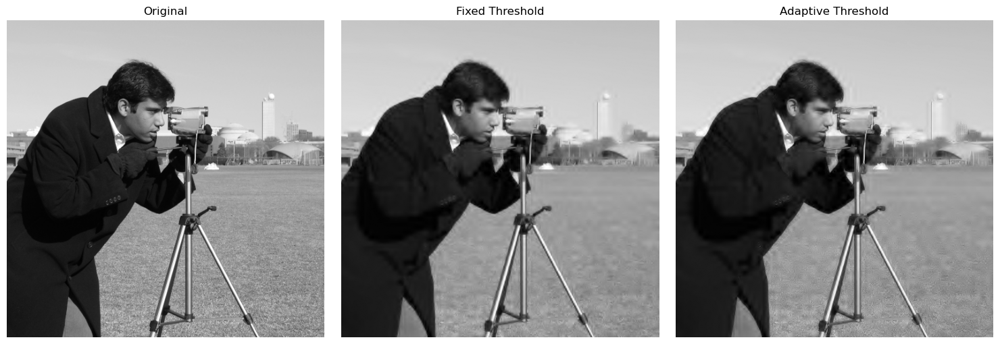

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from skimage import data, color

# Load a test image
test_image = data.camera()  # grayscale 512x512
# Or convert an RGB image to grayscale
# test_image = color.rgb2gray(data.astronaut()) * 255

def adaptive_threshold(coeffs, percentile=90):
    """Apply adaptive thresholding based on coefficient statistics"""
    cA, details = coeffs[0], coeffs[1:]
    adaptive_coeffs = [cA]  # Keep approximation unchanged
    
    for detail_level in details:
        adaptive_detail = []
        for detail_coeff in detail_level:
            threshold = np.percentile(np.abs(detail_coeff), percentile)
            thresholded = pywt.threshold(detail_coeff, threshold, mode='soft')
            adaptive_detail.append(thresholded)
        adaptive_coeffs.append(tuple(adaptive_detail))
    
    return adaptive_coeffs

# Perform decomposition
coeffs = pywt.wavedec2(test_image, 'db4', level=3)

# Fixed threshold
fixed_coeffs = list(coeffs)
fixed_coeffs[0] = coeffs[0]
for i in range(1, len(coeffs)):
    fixed_coeffs[i] = tuple([
        pywt.threshold(detail, 25, mode='soft') for detail in coeffs[i]
    ])

# Adaptive threshold
adaptive_coeffs = adaptive_threshold(coeffs, percentile=85)

# Reconstruct both
fixed_recon = pywt.waverec2(fixed_coeffs, 'db4')
adaptive_recon = pywt.waverec2(adaptive_coeffs, 'db4')

# Compare results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(test_image, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(np.clip(fixed_recon, 0, 255).astype(np.uint8), cmap='gray')
axes[1].set_title('Fixed Threshold')
axes[1].axis('off')

axes[2].imshow(np.clip(adaptive_recon, 0, 255).astype(np.uint8), cmap='gray')
axes[2].set_title('Adaptive Threshold')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('./output/adaptive_thresholding_comparison.png', dpi=300)
plt.show()


## 5.8 File Format Integration

In [ ]:
import numpy as np
import pywt
from skimage import io, data, color, metrics

def save_compressed_image(image, output_path, wavelet='db4', threshold=25, levels=3):
    """Save compressed image with metadata"""
    
    # Compress image
    if len(image.shape) == 3:
        compressed = compress_color_image_advanced(image, wavelet=wavelet, levels=levels, compression_ratio=threshold/100)
    else:
        compressed, _, _ = multilevel_compress(image, wavelet, levels, threshold)
    
    # Save compressed image
    io.imsave(output_path, compressed)
    
    # Save compression metadata
    metadata = {
        'wavelet': wavelet,
        'threshold': threshold,
        'levels': levels,
        'original_shape': image.shape,
        'compressed_size': compressed.nbytes
    }
    
    return compressed, metadata

# Example usage
compressed_img, metadata = save_compressed_image(
    data.astronaut(), 
    'compressed_astronaut.png', 
    wavelet='db4', 
    threshold=30
)

print("Compression Metadata:")
for key, value in metadata.items():
    print(f"{key}: {value}")

Compression Metadata:
wavelet: db4
threshold: 30
levels: 3
original_shape: (512, 512, 3)
compressed_size: 786432


## 5.9 Advanced Applications and Case Studies

### 5.9.1 Medical Image Compression Case Study

Medical Image Compression Case Study
Loading medical image...
Compression ratio 0.1: Full PSNR = 49.2 dB, ROI PSNR = 49.2 dB
Compression ratio 0.2: Full PSNR = 46.5 dB, ROI PSNR = 46.4 dB
Compression ratio 0.3: Full PSNR = 44.9 dB, ROI PSNR = 44.6 dB
Compression ratio 0.4: Full PSNR = 43.7 dB, ROI PSNR = 43.4 dB


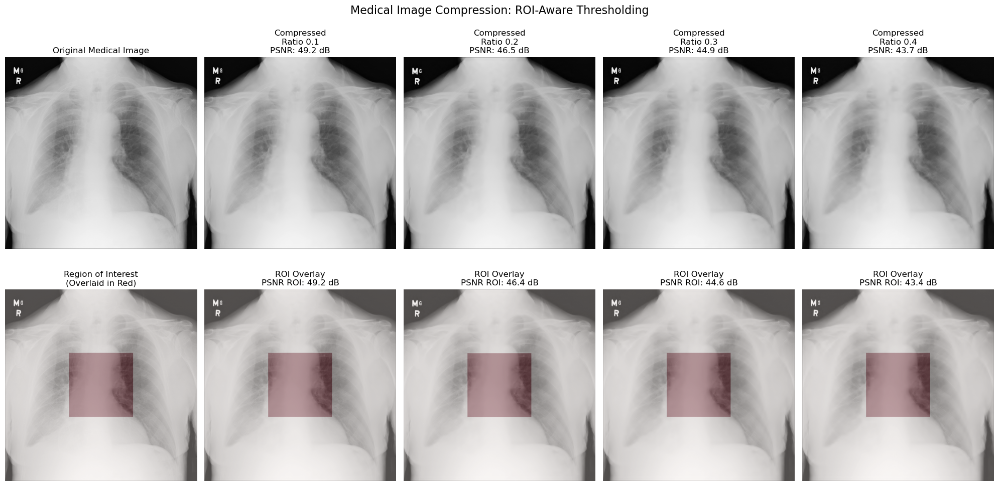

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage import io, color, metrics, img_as_ubyte

def medical_image_compression_case_study(image_path):
    """
    Case study: Medical image compression with region-of-interest preservation
    """
    print("Medical Image Compression Case Study")
    print("=" * 50)
    print("Loading medical image...")

    # Load medical image from file
    medical_image = io.imread(image_path)
    
    # Convert to grayscale if needed
    if medical_image.ndim == 3:
        medical_image = color.rgb2gray(medical_image)
        medical_image = img_as_ubyte(medical_image)

    # Add simulated ROI mask (important anatomical structures)
    roi_mask = np.zeros(medical_image.shape, dtype=bool)
    h, w = medical_image.shape
    roi_mask[h//3:2*h//3, w//3:2*w//3] = True  # Central region

    # Define compression ratios for testing
    compression_ratios = [0.1, 0.2, 0.3, 0.4]

    results = []
    fig, axes = plt.subplots(2, len(compression_ratios) + 1, figsize=(20, 10))

    # Show original image
    axes[0, 0].imshow(medical_image, cmap='gray')
    axes[0, 0].set_title('Original Medical Image')
    axes[0, 0].axis('off')

    # Show ROI mask overlaid
    axes[1, 0].imshow(medical_image, cmap='gray')
    axes[1, 0].imshow(roi_mask, cmap='Reds', alpha=0.3)
    axes[1, 0].set_title('Region of Interest\n(Overlaid in Red)')
    axes[1, 0].axis('off')

    for i, comp_ratio in enumerate(compression_ratios):
        # Wavelet decomposition
        coeffs = pywt.wavedec2(medical_image, 'bior4.4', level=4)
        coeffs_adaptive = [coeffs[0]]  # Keep approximation

        # ROI-aware thresholding
        for level in coeffs[1:]:
            level_thresh = []
            for detail in level:
                threshold = np.std(detail) * comp_ratio
                level_thresh.append(pywt.threshold(detail, threshold, mode='soft'))
            coeffs_adaptive.append(tuple(level_thresh))

        # Reconstruct compressed image
        compressed_image = pywt.waverec2(coeffs_adaptive, 'bior4.4')
        compressed_image = np.clip(compressed_image, 0, 255).astype(np.uint8)

        # Standard PSNR over full image
        psnr_full = metrics.peak_signal_noise_ratio(medical_image, compressed_image)
        # PSNR over ROI only
        psnr_roi = metrics.peak_signal_noise_ratio(medical_image[roi_mask], compressed_image[roi_mask])

        results.append({
            'compression_ratio': comp_ratio,
            'psnr_full': psnr_full,
            'psnr_roi': psnr_roi
        })

        # Display compressed images
        axes[0, i + 1].imshow(compressed_image, cmap='gray')
        axes[0, i + 1].set_title(f'Compressed\nRatio {comp_ratio:.1f}\nPSNR: {psnr_full:.1f} dB')
        axes[0, i + 1].axis('off')

        axes[1, i + 1].imshow(compressed_image, cmap='gray')
        axes[1, i + 1].imshow(roi_mask, cmap='Reds', alpha=0.3)
        axes[1, i + 1].set_title(f'ROI Overlay\nPSNR ROI: {psnr_roi:.1f} dB')
        axes[1, i + 1].axis('off')

        print(f"Compression ratio {comp_ratio:.1f}: Full PSNR = {psnr_full:.1f} dB, ROI PSNR = {psnr_roi:.1f} dB")

    plt.tight_layout()
    plt.suptitle('Medical Image Compression: ROI-Aware Thresholding', fontsize=16, y=1.02)
    plt.savefig('./output/medical_image_compression_case_study.png', dpi=300)
    plt.show()

    return results

# Example usage
medical_results = medical_image_compression_case_study('./data/lung_image.png')


### 5.9.2 Satellite Image Compression Case Study

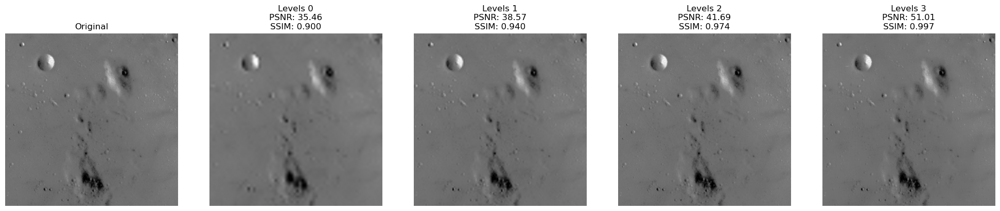

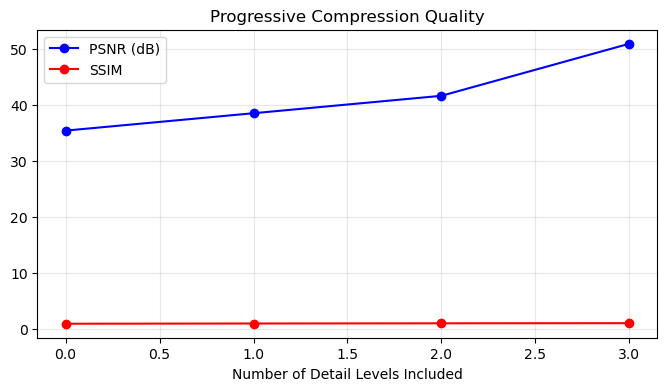

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage import metrics, color
from skimage import img_as_float

class OptimizedWaveletCompressor:
    def __init__(self, wavelet='db4', level=3):
        self.wavelet = wavelet
        self.level = level

    @staticmethod
    def pad_image_for_wavelet(image: np.ndarray, levels: int) -> np.ndarray:
        rows, cols = image.shape
        new_rows = (rows + 2**levels - 1) // (2**levels) * (2**levels)
        new_cols = (cols + 2**levels - 1) // (2**levels) * (2**levels)
        pad_rows = new_rows - rows
        pad_cols = new_cols - cols
        return np.pad(image, ((0, pad_rows), (0, pad_cols)), mode='symmetric')

    def progressive_compression(self, image: np.ndarray, max_levels=None):
        """Progressively reconstruct image from approximation to full detail"""
        if image.ndim == 3:
            image_gray = color.rgb2gray(image) * 255
        else:
            image_gray = image * 255 if image.max() <= 1 else image

        image_gray = np.clip(image_gray, 0, 255).astype(np.uint8)
        image_gray = self.pad_image_for_wavelet(image_gray, self.level)
        max_levels = max_levels or self.level

        # Full decomposition
        coeffs = pywt.wavedec2(image_gray, self.wavelet, level=max_levels)
        n_levels = len(coeffs) - 1

        psnr_list, ssim_list = [], []

        fig, axes = plt.subplots(1, n_levels + 2, figsize=(4*(n_levels+2), 4))
        axes[0].imshow(image_gray, cmap='gray')
        axes[0].set_title("Original")
        axes[0].axis('off')

        # Progressive reconstruction
        for i in range(1, n_levels + 2):
            # Use approximation + first i-1 detail levels
            progressive_coeffs = [coeffs[0]] + coeffs[1:i]
            # Fill remaining levels with zeros
            while len(progressive_coeffs) < len(coeffs):
                detail_shape = coeffs[len(progressive_coeffs)][0].shape
                progressive_coeffs.append(tuple([np.zeros(detail_shape) for _ in range(3)]))

            reconstructed = pywt.waverec2(progressive_coeffs, self.wavelet)
            reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

            psnr_val = metrics.peak_signal_noise_ratio(image_gray, reconstructed)
            ssim_val = metrics.structural_similarity(image_gray, reconstructed, data_range=255)
            psnr_list.append(psnr_val)
            ssim_list.append(ssim_val)

            axes[i].imshow(reconstructed, cmap='gray')
            axes[i].set_title(f'Levels {i-1}\nPSNR: {psnr_val:.2f}\nSSIM: {ssim_val:.3f}')
            axes[i].axis('off')

        plt.tight_layout()
        plt.savefig('./output/progressive_compression_steps.png', dpi=300)
        plt.show()

        # Plot PSNR/SSIM vs levels
        levels_range = list(range(n_levels + 1))
        plt.figure(figsize=(8, 4))
        plt.plot(levels_range, psnr_list, 'b-o', label='PSNR (dB)')
        plt.plot(levels_range, ssim_list, 'r-o', label='SSIM')
        plt.xlabel('Number of Detail Levels Included')
        plt.title('Progressive Compression Quality')
        plt.grid(True)
        plt.legend()
        plt.savefig('./output/progressive_compression_quality.png', dpi=300)
        plt.show()

        return psnr_list, ssim_list

# Example usage
from skimage import data
# Load satellite-like image
satellite_img = img_as_float(data.moon())  # Use moon image as satellite proxy
compressor = OptimizedWaveletCompressor(wavelet='bior4.4', level=3)
psnr_list, ssim_list = compressor.progressive_compression(satellite_img, max_levels=3)

